# 01 · Exploring the data

Week 1 is for understanding the data before modelling it. This notebook walks through:

1. **How imbalanced is UVP6Net?** Class counts at both taxonomic levels.
2. **What do the classes look like?** Image galleries.
3. **Size matters.** Object sizes per class, and what resizing does to them.
4. **Is the NOC test set different?** Backgrounds, sizes, features and sampling context.
5. **What does a baseline get wrong?** Per-class results and predicted class mix.

Run the cells top to bottom. You need `python scripts/download_uvp6net.py` (labels, features and
images) and `python scripts/download_noc_uvp6.py`. Section 5 also needs a baseline run
(`python scripts/train_features.py`).

Every section ends with **questions**. Discuss them as a team, since they lead straight to the methods
you'll compare in weeks 2 and 3.

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from plankton.data import FEATURES, load_classes, load_noc, load_uvp6net, load_uvp6net_features
from plankton.images import load_image
from plankton.viz import show_images

pd.set_option("display.max_rows", 60)
plt.rcParams["figure.dpi"] = 100

## 1 · How imbalanced is UVP6Net?

In [30]:
# Create a Pandas dataframe using the `load_uvp6net()`` function, found in ~/src/plankton/data.py
df = load_uvp6net()
print(f"{len(df):,} images  |  {df.level1.nunique()} level-1 classes  |  {df.level2.nunique()} level-2 classes")
df.split.value_counts()

634,459 images  |  54 level-1 classes  |  32 level-2 classes


split
train    444091
test      95196
valid     95172
Name: count, dtype: int64

Largest class: detritus = 80.2% of all images
Smallest class: Trachymedusae = 87 images
Imbalance ratio (largest / smallest): 5,848x


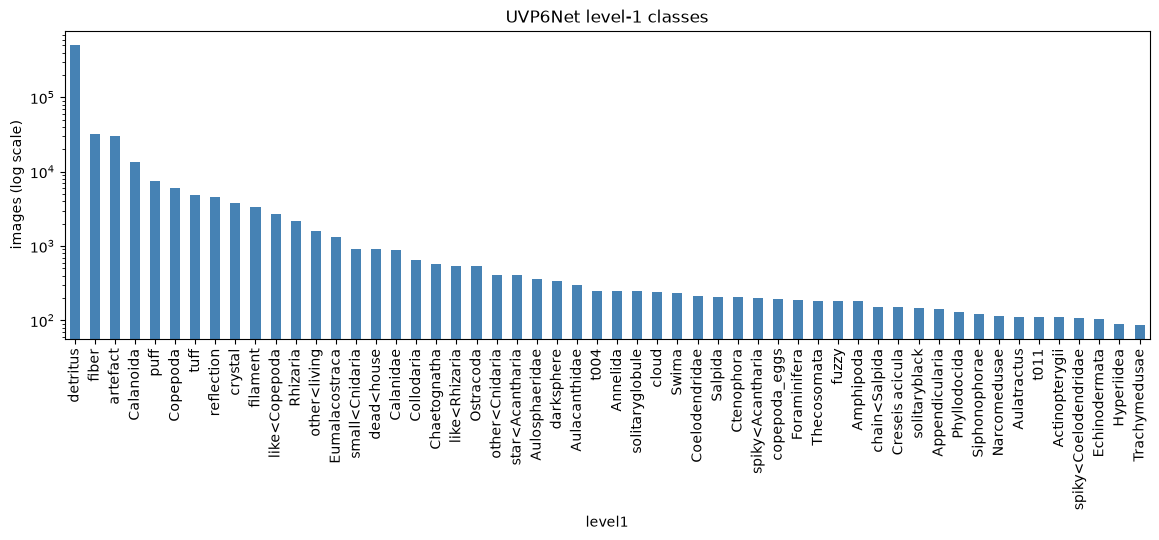

In [31]:
counts = df.level1.value_counts()
share = counts / counts.sum()
print(f"Largest class: {counts.index[0]} = {share.iloc[0]:.1%} of all images")
print(f"Smallest class: {counts.index[-1]} = {counts.iloc[-1]} images")
print(f"Imbalance ratio (largest / smallest): {counts.iloc[0] / counts.iloc[-1]:,.0f}x")

fig, ax = plt.subplots(figsize=(14, 4))
counts.plot.bar(ax=ax, logy=True, color="steelblue")
ax.set_ylabel("images (log scale)")
ax.set_title("UVP6Net level-1 classes")
plt.show()

In [32]:
# Level 2 groups level-1 classes. Which level-1 classes are merged into each level-2 class?
classes = load_classes()
(classes.groupby("level2")
        .agg(n_level1=("level1", "size"), level1=("level1", ", ".join), images=("n_train", "sum"))
        .sort_values("images", ascending=False))

,n_level1,level1,images
level2,,,
detritus,1,detritus,356171
fiber,1,fiber,22814
artefact,1,artefact,21097
Copepoda,5,"Calanidae, Calanoida, Copepoda, copepoda_eggs,...",16387
Trichodesmium,2,"puff, tuff",8602
reflection,1,reflection,3215
crystal,1,crystal,2638
filament,1,filament,2314
Rhizaria,2,"like<Rhizaria, Rhizaria",1922


In [33]:
# A trivial 'classifier' that always predicts the majority class:
valid = df[df.split == "valid"]     # Filter dataframe to only include rows where "split" column = "valid"
acc = (valid.level1 == "detritus").mean()   # Compare each label with "detritus". True = 1, False = 0. Calculate mean
n_classes = valid.level1.nunique()      # Count number of unique classes in level1 column
print(f"Always 'detritus': accuracy {acc:.1%}, but recall is 1 for one class and 0 for the other {n_classes - 1}.")
print(f"  -> balanced accuracy = {1 / n_classes:.3f}, macro F1 ~ {2 * acc / (1 + acc) / n_classes:.3f}")

Always 'detritus': accuracy 80.2%, but recall is 1 for one class and 0 for the other 53.
  -> balanced accuracy = 0.019, macro F1 ~ 0.016


**Questions**
* Why is accuracy useless here? What do macro F1 and balanced accuracy reward instead?
* Some level-1 classes have ~100 training images. What does a CNN with millions of parameters do with 100 examples?
* Level 1 or level 2: which would an ecologist need, and which is easier to learn?

## 2 · What do the classes look like?

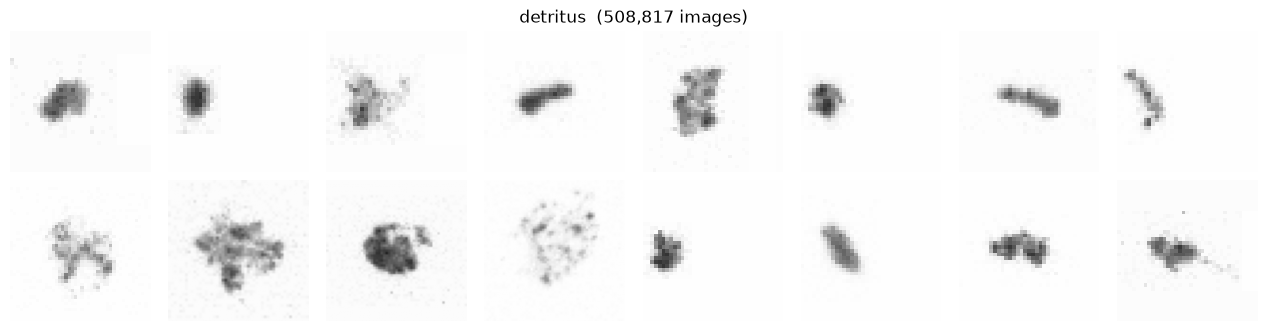

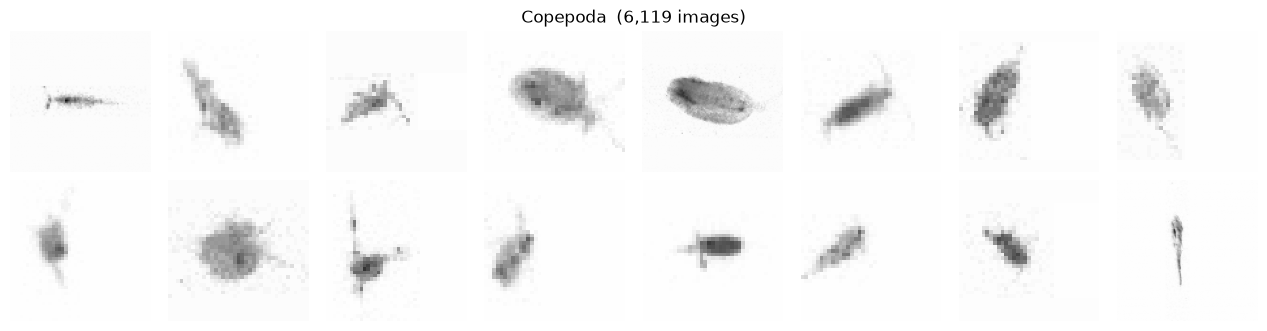

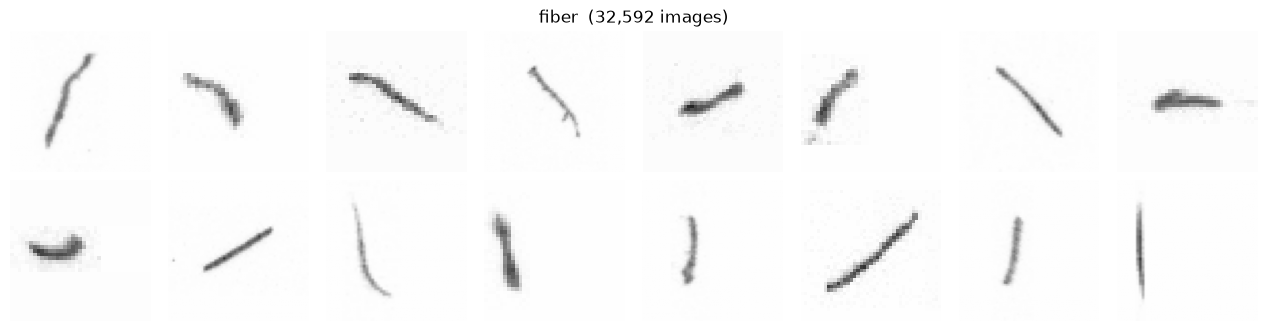

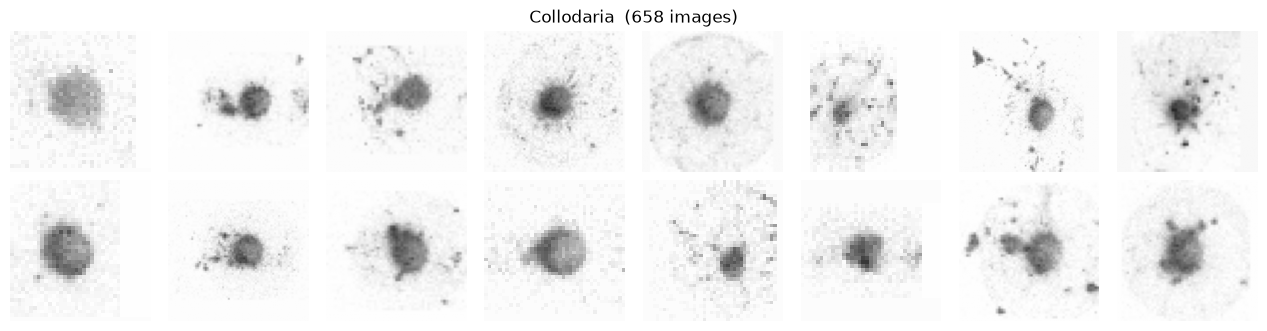

In [41]:
def gallery(cls, n=16, level="level1", split="train", seed=0, **kw):
    sub = df[(df[level] == cls) & (df.split == split)]
    sub = sub.sample(min(n, len(sub)), random_state=seed)
    fig = show_images(sub.path.tolist(), ncols=8, **kw)
    fig.suptitle(f"{cls}  ({len(df[df[level] == cls]):,} images)", y=1.02)
    plt.show()

for cls in ["detritus", "Copepoda", "fiber", "Collodaria"]:
    gallery(cls)

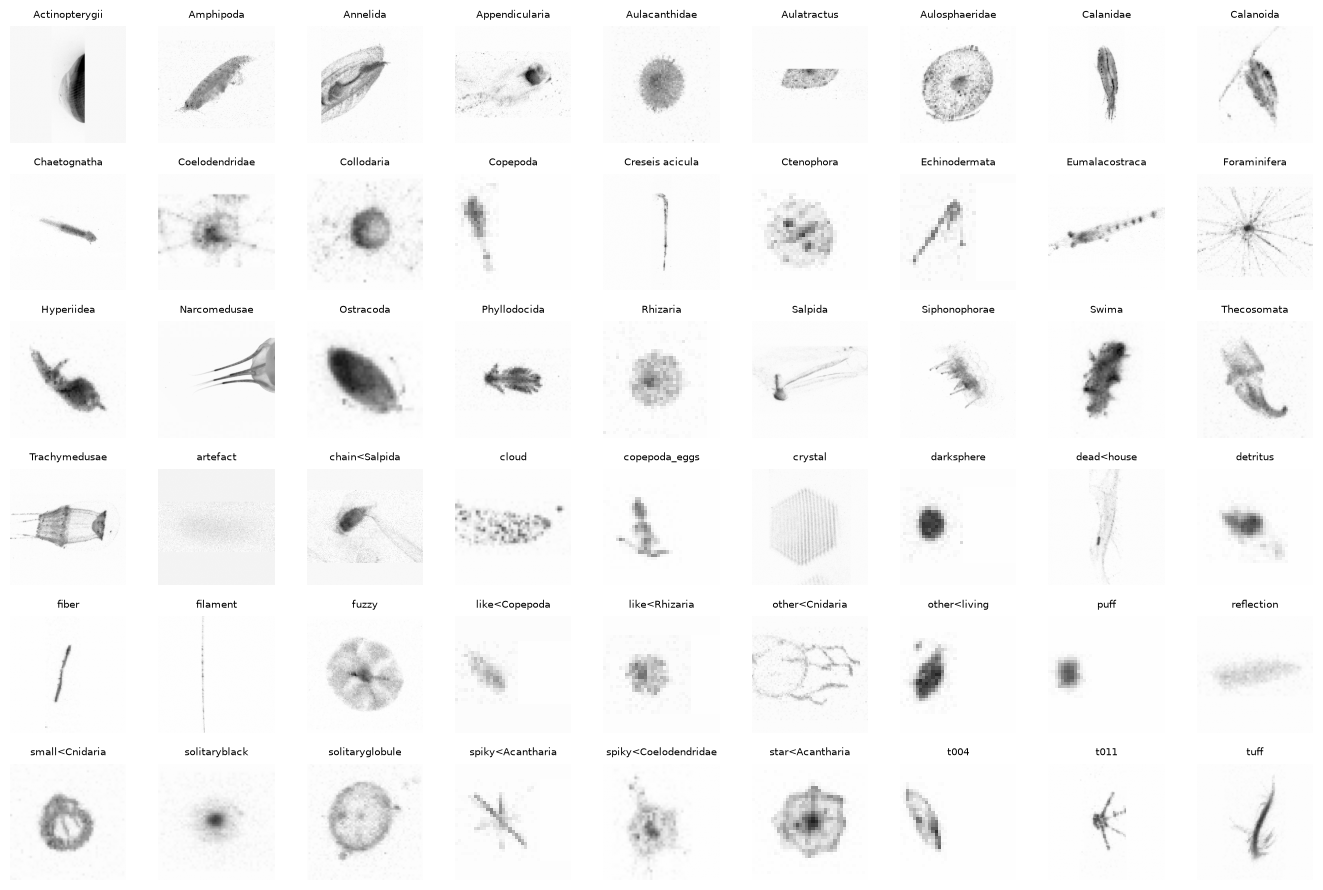

In [35]:
# One random image from every level-1 class
pick = df[df.split == "train"].groupby("level1").sample(1, random_state=1).sort_values("level1")
show_images(pick.path.tolist(), titles=pick.level1.tolist(), ncols=9, size=1.5)
plt.show()

Try `gallery("like<Copepoda")` vs `gallery("Copepoda")`, or `gallery("artefact")` vs `gallery("detritus")`.

**Questions**
* Which classes could *you* not tell apart? If humans struggle, what should we expect of a model,
  and are some errors more acceptable than others?
* Do the images have a natural orientation? Which augmentations are safe?

## 3 · Size matters

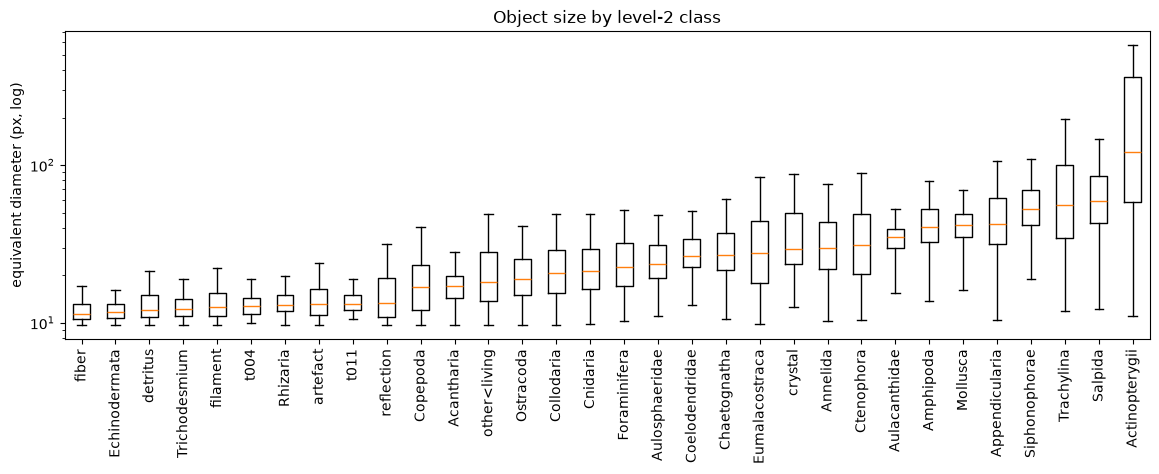

In [36]:
feats = load_uvp6net_features()
feats["esd_px"] = 2 * np.sqrt(feats["area"] / np.pi)   # equivalent spherical diameter, in pixels
order = feats.groupby("level2").esd_px.median().sort_values().index

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot([feats.loc[feats.level2 == c, "esd_px"] for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=90)
ax.set_yscale("log")
ax.set_ylabel("equivalent diameter (px, log)")
ax.set_title("Object size by level-2 class")
plt.show()

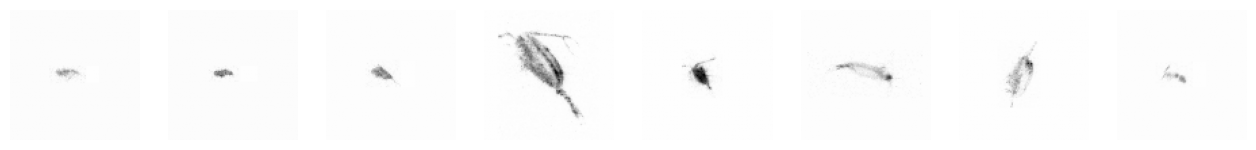

In [37]:
# The CNN baseline resizes every image to 128 x 128, so a tiny copepod and a large one look the
# same size. Shown here at true relative scale:
sub = df[(df.level2 == "Copepoda") & (df.split == "train")].sample(8, random_state=3)
show_images(sub.path.tolist(), ncols=8, keep_scale=True)
plt.show()

**Questions**
* Size separates some classes well. The CNN can't see it after resizing; the handcrafted features
  (`area`, `feret`, ...) can. How could you give a CNN both?
* Images range from ~20 to ~1000 px. What does upsampling a 20 px image to 128 px do?

## 4 · Is the NOC test set different?

The NOC images come from a different deployment (June to August 2024, the North Atlantic, south of Iceland).
We can't see their labels, but we *can* compare the images and features.

3,586 NOC images from 162 samples, 2024-06-09 to 2024-08-05


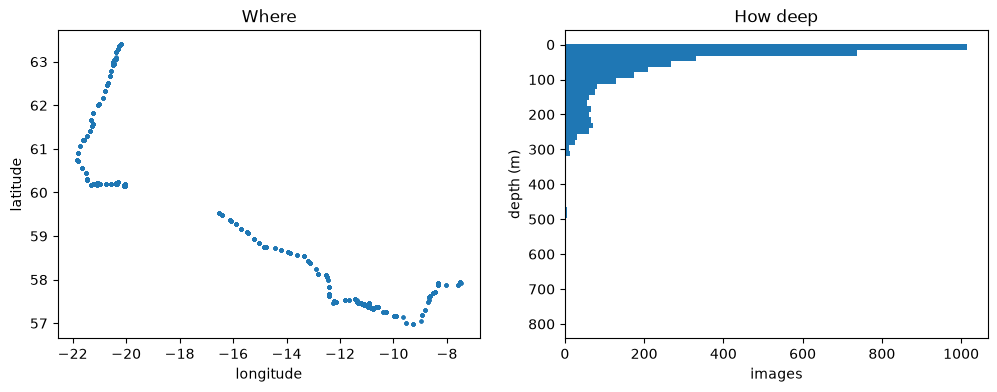

In [38]:
noc = load_noc()
print(f"{len(noc):,} NOC images from {noc.sample_id.nunique()} samples, {noc.date.min()} to {noc.date.max()}")

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
a.scatter(noc.lon, noc.lat, s=4)
a.set(xlabel="longitude", ylabel="latitude", title="Where")
b.hist(noc.depth_m, bins=50, orientation="horizontal")
b.invert_yaxis()
b.set(xlabel="images", ylabel="depth (m)", title="How deep")
plt.show()

       UVP6Net     NOC
count   1000.0  1000.0
mean     253.2   251.4
std        1.4     3.8
min      237.0   233.0
25%      253.0   252.0
50%      254.0   252.0
75%      254.0   253.0
max      254.0   254.0


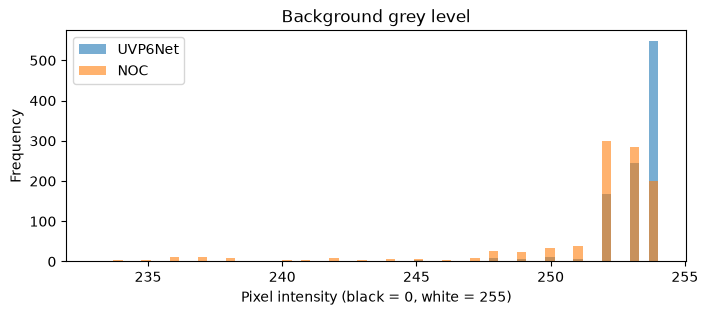

In [ ]:
# Estimate background brightness: median of each image's border pixels
def background(path):
    # Load image from a specified path and covert this image into a np array
    a = np.asarray(load_image(path))
    # Extract first row of pixels, last row, first column and last column, and concatenate into array
    # Note: four corner pixels are included twice - fine for this analysis
    # Find the median of this array
    return np.median(np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]]))

sample_uvp = df.sample(1000, random_state=0).path   # Randomly sample 1000 rows from the uvp6net dataframe
# Create a df that contains the pixel values for each image in sample_uvp and the NOC dataset
bg = pd.DataFrame({"UVP6Net": [background(p) for p in sample_uvp],
                   "NOC": [background(p) for p in noc.path.sample(1000, random_state=0)]})
print(bg.describe().round(1))   # Return a statistical description of the data in the DataFrame
bg.plot.hist(bins=60, alpha=0.6, figsize=(8, 3), title="Background grey level")
plt.xlabel("Pixel intensity (black = 0, white = 255)")
plt.show()

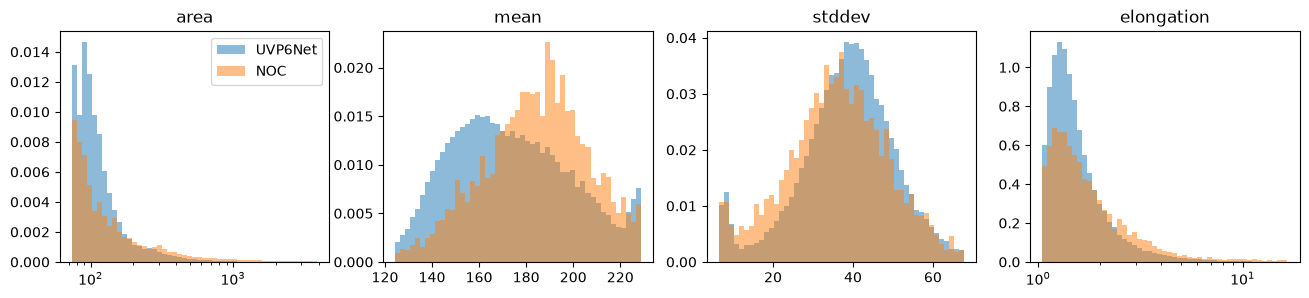

In [14]:
# Compare a few handcrafted features (UVP6Net subsample vs NOC)
ref = feats.sample(50_000, random_state=0)
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, f in zip(axes, ["area", "mean", "stddev", "elongation"]):
    log = f in ("area", "elongation")  # long-tailed: compare on a log scale
    lo, hi = np.percentile(pd.concat([ref[f], noc[f]]), [1, 99])
    bins = np.geomspace(max(lo, 1e-3), hi, 50) if log else np.linspace(lo, hi, 50)
    ax.hist(ref[f], bins=bins, density=True, alpha=0.5, label="UVP6Net")
    ax.hist(noc[f], bins=bins, density=True, alpha=0.5, label="NOC")
    ax.set(title=f, xscale="log" if log else "linear")
axes[0].legend()
plt.show()

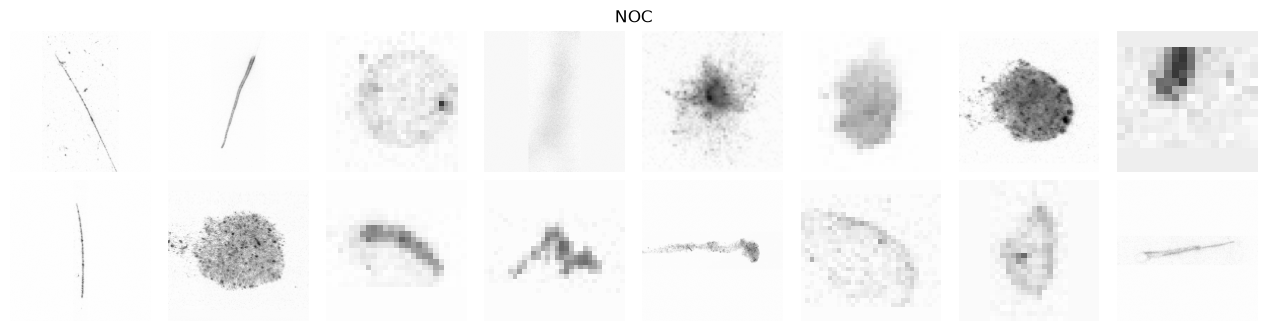

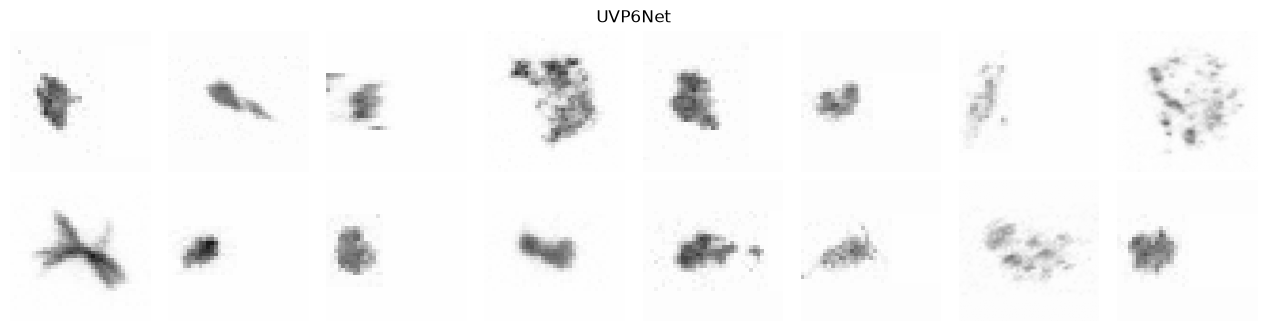

In [15]:
# NOC images side by side with random UVP6Net images
show_images(noc.path.sample(16, random_state=0).tolist(), ncols=8)
plt.suptitle("NOC", y=1.02)
show_images(df.path.sample(16, random_state=0).tolist(), ncols=8)
plt.suptitle("UVP6Net", y=1.02)
plt.show()

**Questions**
* How different are the backgrounds, really (look at the spread, not just the median)? Could a model
  pick up cues like background brightness or noise during training, and would they transfer to NOC?
  Which preprocessing or augmentation would make it robust to them?
* The feature distributions differ. Is that because the *classes* differ (a different plankton
  community) or because the *imaging* differs? How could you tell them apart?
* Remember: NOC contains one class that's absent from UVP6Net. What would make an object look
  "out of distribution"?

## 5 · What does a baseline get wrong?

Needs `python scripts/train_features.py` (writes `outputs/rf/`). Change `RUN` to look at another run.

In [2]:
import sys
from pathlib import Path

RUN = Path("../outputs/rf")
sys.path.insert(0, "../scripts")
import evaluate as ev

classes = ev.load_classes()
truth = ev.load_truth("uvp6net-test", level=1, data_dir=Path("../data/uvp6net"))
pred = ev.clean_predictions(ev.read_predictions(RUN / "predictions_uvp6net_test.csv"), 1, classes)
result = ev.evaluate(truth, pred, 1, classes)
print({k: round(v, 3) for k, v in result["metrics"]["unweighted"].items()})
result["table"].sort_values("f1")

{'accuracy': 0.907, 'balanced_accuracy': 0.257, 'macro_f1': 0.314}


,support,precision,recall,f1
class,,,,
spiky<Acantharia,31,0.000000,0.000000,0.000000
Hyperiidea,14,0.000000,0.000000,0.000000
Annelida,38,0.000000,0.000000,0.000000
Aulatractus,17,0.000000,0.000000,0.000000
copepoda_eggs,30,0.000000,0.000000,0.000000
like<Copepoda,408,0.000000,0.000000,0.000000
cloud,37,0.000000,0.000000,0.000000
Coelodendridae,32,0.000000,0.000000,0.000000
t004,38,0.000000,0.000000,0.000000


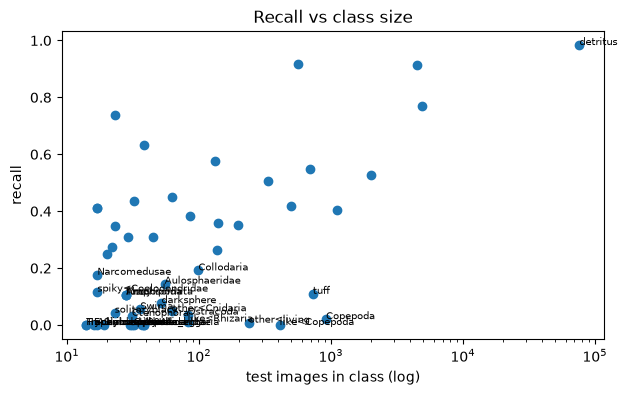

In [17]:
# Recall vs class size: is the model only good at big classes?
t = result["table"]
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(t.support, t.recall)
for name, r in t.iterrows():
    if r.recall < 0.2 or r.support > 5000:
        ax.annotate(name, (r.support, r.recall), fontsize=7)
ax.set(xscale="log", xlabel="test images in class (log)", ylabel="recall", title="Recall vs class size")
plt.show()

In [18]:
# Biggest confusions (true -> predicted), excluding correct predictions
cm = result["confusion"].copy()
for c in cm.index:
    if c in cm.columns:
        cm.loc[c, c] = 0
pairs = cm.stack()
pairs[pairs > 0].sort_values(ascending=False).head(15)

true \ predicted           
fiber             detritus     1075
Calanoida         detritus      924
Copepoda          detritus      845
detritus          fiber         686
puff              detritus      662
tuff              detritus      467
like<Copepoda     detritus      397
artefact          detritus      329
filament          detritus      221
reflection        detritus      213
other<living      detritus      197
detritus          artefact      176
tuff              fiber         171
detritus          Calanoida     160
Rhizaria          detritus      156
dtype: int64

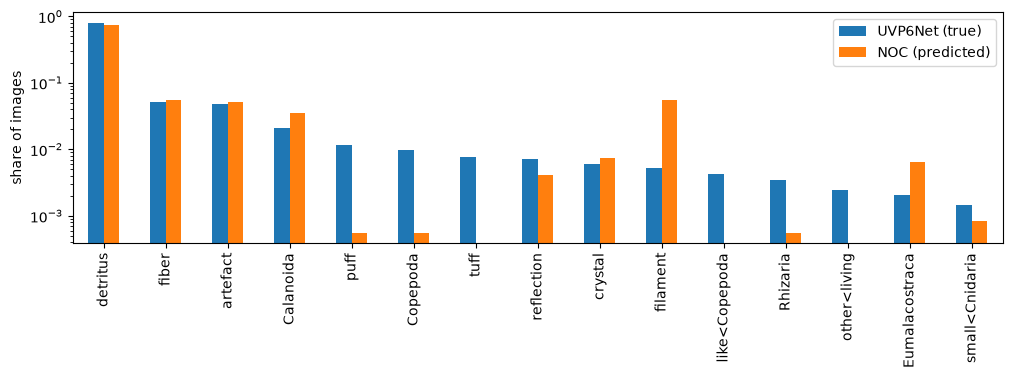

In [19]:
# Predicted class mix on NOC vs the true UVP6Net mix
noc_pred = pd.read_csv(RUN / "predictions_noc.csv")
mix = pd.DataFrame({"UVP6Net (true)": df.level1.value_counts(normalize=True),
                    "NOC (predicted)": noc_pred.label.value_counts(normalize=True)}).fillna(0)
mix.sort_values("UVP6Net (true)", ascending=False).head(15).plot.bar(figsize=(12, 3), logy=True)
plt.ylabel("share of images")
plt.show()

**Questions**
* Which classes have F1 near zero? Are they rare, visually ambiguous, or both?
* Are the confusions "reasonable" (e.g. two copepod classes), or "bad" (plankton called detritus)?
  For carbon and abundance estimates, which errors matter most?
* The NOC images were over-sampled for rare classes, so the true NOC mix differs from UVP6Net's.
  What does a classifier trained on UVP6Net's priors (80% detritus) do when the priors change?
  Look up *label shift* and *logit adjustment*.

---
**Next:** pick the questions your team finds most interesting, and plan weeks 2-3 around them.
`src/plankton/imbalance.py` is a good place to start coding.